# 03 · The Average Is Not the Risk — Testing a Popular Claim

**CISC7204 Assignment 02 · Pair Project · Class K Pair 14**

## The claim we set out to test

A common argument in aviation commentary is that *"average delays are
improving, but extreme delays are getting worse"* — the average hides a
deteriorating tail. If true, it would be the strongest possible argument for
replacing mean-delay charts with tail-probability charts.

**We tested it on 2024 data and it did not hold.** Mean delay and the tail
probability move together almost perfectly across months (Pearson r = 0.998,
see §3). Reporting this null result is more useful than hiding it: it tells
us exactly what the mean *can* and *cannot* be trusted to say.

What survives the test, and what this notebook therefore establishes:

1. **The distribution is extremely concentrated** — the worst 1% of flights
   generate 25% of all delay minutes (§2).
2. **The mean is not a level a reader can interpret** — the median flight
   arrives 6 minutes *early* while the mean flight arrives 7 minutes late,
   and 73% of flights arrive earlier than the mean (§1). Its monthly swing
   (19 minutes) has no fixed relationship to the swing in risk (§3).
3. **The tail is structurally different from the body** — the cause mix
   shifts as the threshold rises (§5), which is why the modelling notebook
   needs a separate tail model.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SRC = Path.cwd().parent / "src" if Path.cwd().name == "notebooks" else Path.cwd() / "src"
sys.path.insert(0, str(SRC.resolve()))

import common
from common import (ACCENT, CAUSE_COLORS, CAUSE_COLS, CAUSE_LABELS,
                    FAMILY_COLORS, INK, MUTED, OUT_DIR, PROCESSED_DIR, save_fig)

agg = pd.read_pickle(PROCESSED_DIR / "aggregates.pkl")

df = pd.read_parquet(common.FLIGHTS_PARQUET,
                     columns=["Month", "Reporting_Airline", "ArrDelay",
                              "ArrDelayMinutes", "is_tail60", "is_tail180"]
                     + CAUSE_COLS)
df = df[df["ArrDelay"].notna()]
print(f"{len(df):,} completed flights with a recorded arrival delay")


6,965,247 completed flights with a recorded arrival delay


## 1 · One number is not enough

Percentiles first. The distance between the 50th and the 99th percentile is
where the entire story lives.


In [2]:
q = df["ArrDelay"].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95,
                             0.99, 0.999])
reading = [
    "1% of flights are this early or earlier",
    "10% this early or earlier",
    "25% this early or earlier",
    "half of all flights are this early or earlier",
    "a quarter of flights are later than this",
    "10% are later than this",
    "5% are later than this",
    "1% are later than this",
    "1 flight in 1,000 is later than this",
]
stats = pd.DataFrame({"percentile": [f"p{int(i * 1000) / 10:g}"
                                     for i in q.index],
                      "arrival delay (min)": q.to_numpy(),
                      "reading": reading})
print(stats.to_string(index=False))
print(f"\nmean {df['ArrDelay'].mean():.1f} min | "
      f"median {df['ArrDelay'].median():.1f} min | "
      f"p99 {df['ArrDelay'].quantile(0.99):.0f} min | "
      f"max {df['ArrDelay'].max():.0f} min")
print(f"mean sits at the "
      f"{100 * (df['ArrDelay'] < df['ArrDelay'].mean()).mean():.1f}th "
      f"percentile of the distribution")


percentile  arrival delay (min)                                       reading
        p1                -37.0       1% of flights are this early or earlier
       p10                -23.0                     10% this early or earlier
       p25                -15.0                     25% this early or earlier
       p50                 -6.0 half of all flights are this early or earlier
       p75                  9.0      a quarter of flights are later than this
       p90                 43.0                       10% are later than this
       p95                 83.0                        5% are later than this
       p99                215.0                        1% are later than this
     p99.9                753.0          1 flight in 1,000 is later than this



mean 7.1 min | median -6.0 min | p99 215 min | max 3803 min
mean sits at the 73.2th percentile of the distribution


The median flight arrives **6 minutes early**. The mean flight arrives
**7 minutes late**. The mean sits at the **73rd percentile**: nearly three
flights in four arrive earlier than the "average" flight. The mean is not a
typical flight — it is a weighted average pulled upward by a minority of very
late ones. Both statements describe 2024 correctly, and a chart showing only
one of them changes the conclusion a reader draws.


## 2 · How concentrated are the delay minutes?

A Lorenz curve: sort every flight from most to least delayed and ask what
share of all delay minutes the worst X% have accumulated by then.


 worst_x_percent_of_flights  share_of_all_delay_minutes_%
                          1                     25.100000
                          5                     57.200001
                         10                     76.099998
                         20                     92.800003
                         50                     99.500000


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig08_lorenz_delay.png


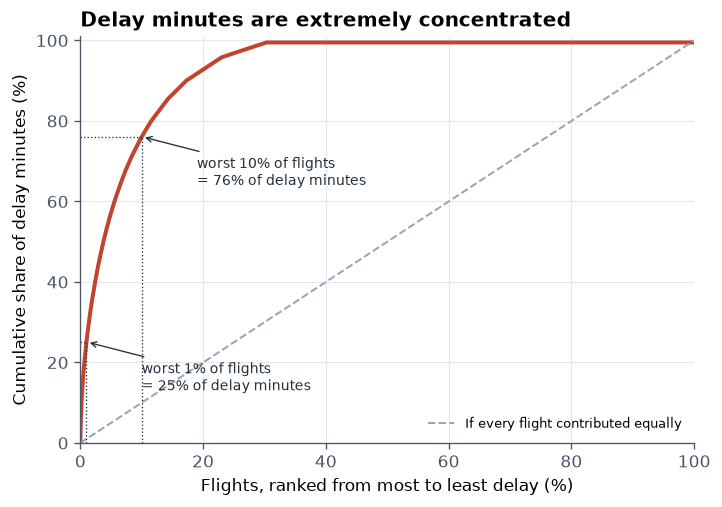

In [3]:
minutes = np.sort(df["ArrDelayMinutes"].to_numpy())[::-1]
cum_share = np.cumsum(minutes) / minutes.sum() * 100
pct_flights = np.arange(1, len(minutes) + 1) / len(minutes) * 100

marks = [1, 5, 10, 20, 50]
concentration = pd.DataFrame({
    "worst_x_percent_of_flights": marks,
    "share_of_all_delay_minutes_%": [cum_share[int(len(minutes) * m / 100) - 1]
                                     for m in marks],
})
print(concentration.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.plot(pct_flights, cum_share, color=ACCENT, linewidth=2.4)
ax.plot([0, 100], [0, 100], color=MUTED, linestyle="--", linewidth=1.2,
        label="If every flight contributed equally")
for mk in (1, 10):
    y = cum_share[int(len(minutes) * mk / 100) - 1]
    ax.plot([mk, mk], [0, y], color=INK, linewidth=0.8, linestyle=":")
    ax.plot([0, mk], [y, y], color=INK, linewidth=0.8, linestyle=":")
    ax.annotate(f"worst {mk}% of flights\n= {y:.0f}% of delay minutes",
                xy=(mk, y), xytext=(mk + 9, y - 12), fontsize=8.2, color=INK,
                arrowprops=dict(arrowstyle="->", color=INK, linewidth=0.8))
ax.set_xlim(0, 100)
ax.set_ylim(0, 101)
ax.set_xlabel("Flights, ranked from most to least delay (%)")
ax.set_ylabel("Cumulative share of delay minutes (%)")
ax.set_title("Delay minutes are extremely concentrated", loc="left")
ax.legend(loc="lower right", fontsize=8)
ax.grid(color="#E3E8EC", linewidth=0.7)
ax.set_axisbelow(True)
save_fig(fig, "fig08_lorenz_delay")
plt.show()


## 3 · Testing the claim: does the mean track the tail?

This section is the reason the notebook exists. For each month we compute
the mean, the 90th and 99th percentiles, and the share of flights delayed
60 or 180 minutes, then correlate them.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig09_mean_vs_tail_by_month.png


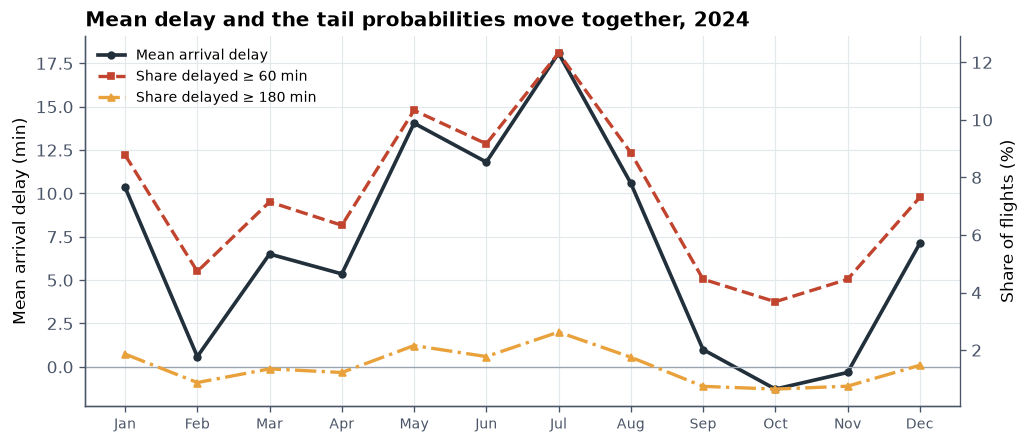

In [4]:
m = agg["by_month"].copy()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9.4, 4.0))
ax.plot(range(1, 13), m["mean_delay"], color=INK, linewidth=2.2, marker="o",
        markersize=4, label="Mean arrival delay")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months, fontsize=8.6)
ax.set_ylabel("Mean arrival delay (min)")
ax.set_title("Mean delay and the tail probabilities move together, 2024",
             loc="left")

ax2 = ax.twinx()
ax2.plot(range(1, 13), m["pct_tail60"], color=ACCENT, linewidth=2.0,
         linestyle="--", marker="s", markersize=3.6,
         label="Share delayed ≥ 60 min")
ax2.plot(range(1, 13), m["pct_tail180"], color=FAMILY_COLORS["System"],
         linewidth=2.0, linestyle="-.", marker="^", markersize=4.2,
         label="Share delayed ≥ 180 min")
ax2.set_ylabel("Share of flights (%)")
ax2.spines["right"].set_visible(True)
ax2.spines["top"].set_visible(False)

lines = ax.get_lines()[:1] + ax2.get_lines()[:2]
ax.legend(lines, [ln.get_label() for ln in lines], loc="upper left",
          fontsize=8.2)
ax.grid(color="#E3E8EC", linewidth=0.7)
ax.set_axisbelow(True)
save_fig(fig, "fig09_mean_vs_tail_by_month")
plt.show()


In [5]:
corr = m[["mean_delay", "p90", "p99", "pct_tail60", "pct_tail180"]].corr()
print("Pearson correlations across the 12 months:")
print(corr.round(3).to_string())


Pearson correlations across the 12 months:
             mean_delay    p90    p99  pct_tail60  pct_tail180
mean_delay        1.000  0.998  0.986       0.998        0.993
p90               0.998  1.000  0.984       1.000        0.995
p99               0.986  0.984  1.000       0.986        0.986
pct_tail60        0.998  1.000  0.986       1.000        0.997
pct_tail180       0.993  0.995  0.986       0.997        1.000


### 3.1 The result

The correlation between the monthly mean and the monthly share of flights
delayed 60+ minutes is **0.998**. They never diverge in direction. The
"averages improve while extremes worsen" story is **not supported** by 2024
monthly data, and we report that instead of forcing the narrative.

What the mean still fails at is **magnitude**:


In [6]:
spread = pd.DataFrame({
    "statistic": ["mean delay (min)", "median delay (min)", "p90 (min)",
                  "p99 (min)", "share ≥ 60 min (%)",
                  "share ≥ 180 min (%)"],
    "best month": [m["mean_delay"].min(), m["median_delay"].min(),
                   m["p90"].min(), m["p99"].min(), m["pct_tail60"].min(),
                   m["pct_tail180"].min()],
    "worst month": [m["mean_delay"].max(), m["median_delay"].max(),
                    m["p90"].max(), m["p99"].max(), m["pct_tail60"].max(),
                    m["pct_tail180"].max()],
})
spread["ratio"] = spread["worst month"] / spread["best month"]
print(spread.round(2).to_string(index=False))
print(f"\nA reader told 'mean delay went from {m['mean_delay'].min():.1f} "
      f"to {m['mean_delay'].max():.1f} minutes' has no way to infer that the "
      f"3-hour tail probability went from {m['pct_tail180'].min():.2f}% to "
      f"{m['pct_tail180'].max():.2f}%.")


          statistic  best month  worst month  ratio
   mean delay (min)       -1.28        18.09 -14.10
 median delay (min)       -9.00        -2.00   0.22
          p90 (min)       21.00        73.00   3.48
          p99 (min)      142.00       278.00   1.96
 share ≥ 60 min (%)        3.68        12.32   3.35
share ≥ 180 min (%)        0.64         2.63   4.08

A reader told 'mean delay went from -1.3 to 18.1 minutes' has no way to infer that the 3-hour tail probability went from 0.64% to 2.63%.


So the correct criticism of the mean is **not** that it points the wrong
way. It is that:

* it is not a level anyone can locate themselves in (median −6 vs mean +7);
* it has no fixed relationship to risk: the monthly mean swings from −1.3 to
  +18.1 minutes (and crosses zero), while the 3-hour tail probability swings
  from 0.64% to 2.63%. A 19-minute move in the mean can mean anything from
  "a slightly worse month" to "four times the chance of losing an afternoon";
* it says nothing about **concentration** (worst 1% = 25% of minutes).

A dashboard should therefore show mean, median and tail share **side by
side**, which is what ours does.


## 4 · Where the mean and the tail do disagree: carriers

Across months the two measures agree; across carriers they part company,
because carriers differ in route mix and in how their delay is distributed.
Rank them both ways and look at the shifts.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig10_carrier_mean_vs_tail.png


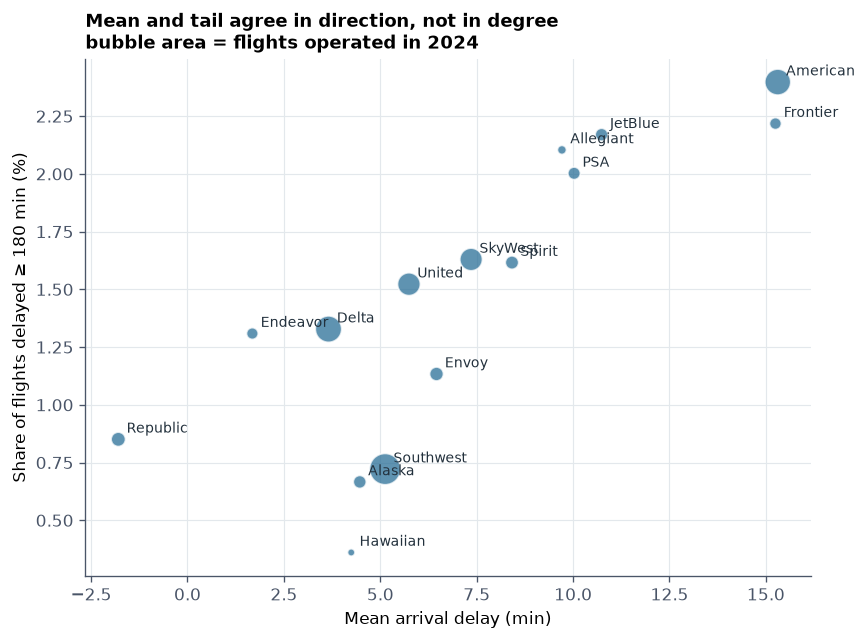

In [7]:
c = agg["by_carrier"].copy()
c = c[c["flights"] > 20_000].copy()
label_map = {"AA": "American", "AS": "Alaska", "B6": "JetBlue", "DL": "Delta",
             "F9": "Frontier", "G4": "Allegiant", "HA": "Hawaiian",
             "NK": "Spirit", "OO": "SkyWest", "UA": "United",
             "WN": "Southwest", "YX": "Republic", "9E": "Endeavor",
             "MQ": "Envoy", "OH": "PSA"}
c["carrier"] = (c["Reporting_Airline"].astype(str).map(label_map)
                .fillna(c["Reporting_Airline"].astype(str)))

c["rank_mean"] = c["mean_delay"].rank()
c["rank_tail"] = c["pct_tail180"].rank()
c["rank_shift"] = c["rank_tail"] - c["rank_mean"]

fig, ax = plt.subplots(figsize=(7.8, 5.6))
ax.scatter(c["mean_delay"], c["pct_tail180"], s=c["flights"] / 4000,
           color=FAMILY_COLORS["Internal"], alpha=0.75, edgecolor="white",
           linewidth=1.0)
for _, r in c.iterrows():
    ax.annotate(r["carrier"], (r["mean_delay"], r["pct_tail180"]),
                fontsize=8.2, xytext=(5, 4), textcoords="offset points",
                color=INK)
ax.set_xlabel("Mean arrival delay (min)")
ax.set_ylabel("Share of flights delayed ≥ 180 min (%)")
ax.set_title("Mean and tail agree in direction, not in degree\n"
             "bubble area = flights operated in 2024", loc="left",
             fontsize=10.5)
ax.grid(color="#E3E8EC", linewidth=0.7)
ax.set_axisbelow(True)
save_fig(fig, "fig10_carrier_mean_vs_tail")
plt.show()


In [8]:
print(c[["carrier", "flights", "mean_delay", "pct_tail60", "pct_tail180",
         "rank_mean", "rank_tail", "rank_shift"]]
      .sort_values("rank_shift", key=abs, ascending=False)
      .round(2).to_string(index=False))
rho = c["mean_delay"].corr(c["pct_tail180"], method="spearman")
print(f"\nSpearman rank correlation (mean vs 3-hour tail) = {rho:.2f}")
print("largest rank shifts:")
print(c.reindex(c["rank_shift"].abs().sort_values(ascending=False).index)
      [["carrier", "rank_mean", "rank_tail", "rank_shift"]].head(4)
      .round(0).to_string(index=False))
c.to_csv(OUT_DIR / "carrier_mean_vs_tail.csv", index=False)


  carrier  flights  mean_delay  pct_tail60  pct_tail180  rank_mean  rank_tail  rank_shift
 Endeavor   195072        1.68        6.41         1.31        2.0        6.0         4.0
    Delta   997826        3.66        5.91         1.33        3.0        7.0         4.0
   Alaska   240323        4.47        5.29         0.67        5.0        2.0        -3.0
 Republic   295306       -1.79        4.97         0.85        1.0        4.0         3.0
Southwest  1404597        5.13        5.70         0.72        6.0        3.0        -3.0
    Envoy   275317        6.46        6.94         1.13        8.0        5.0        -3.0
 Hawaiian    77633        4.25        2.64         0.36        4.0        1.0        -3.0
      PSA   223673       10.03        8.63         2.00       12.0       11.0        -1.0
   Spirit   255633        8.42        9.16         1.62       10.0        9.0        -1.0
   United   745818        5.74        7.53         1.52        7.0        8.0         1.0
Allegiant 


Spearman rank correlation (mean vs 3-hour tail) = 0.85
largest rank shifts:
 carrier  rank_mean  rank_tail  rank_shift
Endeavor        2.0        6.0         4.0
   Delta        3.0        7.0         4.0
  Alaska        5.0        2.0        -3.0
Republic        1.0        4.0         3.0


A Spearman correlation around 0.85 means the two rankings broadly agree — but
several carriers shift by three or four places. Those shifts are the
practical argument for showing both measures: a passenger choosing on
"average delay" would rank a carrier differently from a passenger choosing
on "chance of losing an afternoon".


## 5 · The tail has a different cause mix

If long delays were merely short delays scaled up, the cause split would be
identical at every threshold. It is not — which is why the modelling
notebook fits a separate model for the tail.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig11_tail_cause_mix.png


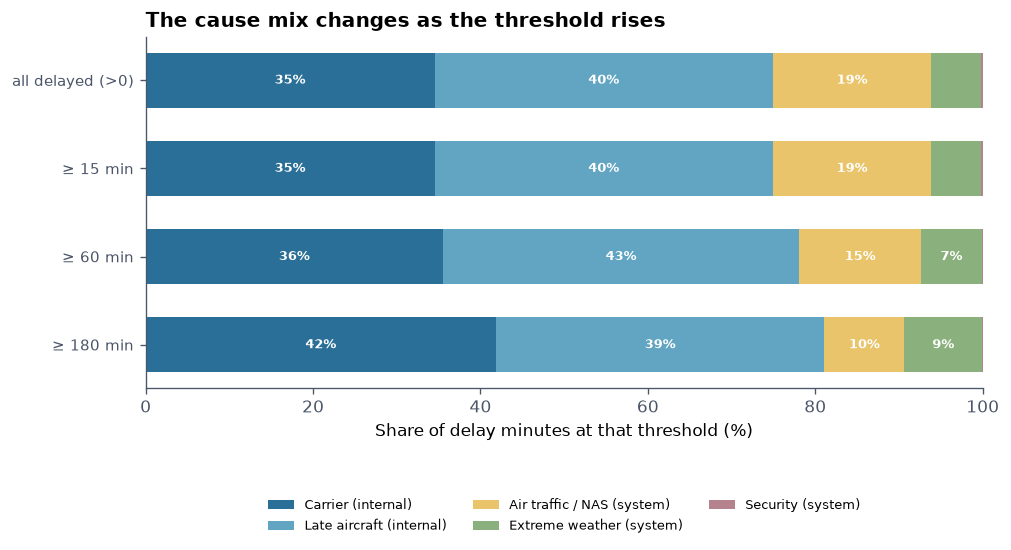

In [9]:
thresholds = {"all delayed (>0)": 0, "≥ 15 min": 15,
              "≥ 60 min": 60, "≥ 180 min": 180}
rows = []
for name, thr in thresholds.items():
    sel = df[(df["ArrDelayMinutes"] > thr) if thr == 0
             else (df["ArrDelayMinutes"] >= thr)]
    totals = sel[CAUSE_COLS].sum()
    rows.append(pd.Series((totals / totals.sum() * 100).to_dict(), name=name))
mix = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.0, 3.8))
bottom = np.zeros(len(mix))
for cause in CAUSE_COLS:
    ax.barh(range(len(mix)), mix[cause], left=bottom, height=0.62,
            color=CAUSE_COLORS[cause], label=CAUSE_LABELS[cause])
    for i, v in enumerate(mix[cause]):
        if v > 7:
            ax.text(bottom[i] + v / 2, i, f"{v:.0f}%", ha="center",
                    va="center", fontsize=8, color="white",
                    fontweight="bold")
    bottom += mix[cause].to_numpy()
ax.set_yticks(range(len(mix)))
ax.set_yticklabels(mix.index, fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of delay minutes at that threshold (%)")
ax.set_title("The cause mix changes as the threshold rises", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3,
          fontsize=7.8)
ax.invert_yaxis()
save_fig(fig, "fig11_tail_cause_mix")
plt.show()


In [10]:
print(mix.round(1).to_string())
mix.to_csv(OUT_DIR / "tail_cause_mix.csv")


                  CarrierDelay  LateAircraftDelay  NASDelay  WeatherDelay  SecurityDelay
all delayed (>0)          34.5               40.4      18.9           6.0            0.2
≥ 15 min                  34.5               40.4      18.9           6.0            0.2
≥ 60 min                  35.5               42.5      14.6           7.2            0.1
≥ 180 min                 41.9               39.2       9.6           9.3            0.1


## 6 · The shape of the distribution

A histogram of raw delay minutes is unreadable: almost all mass sits near
zero and the tail vanishes into one bar. The survival function on a log-log
axis makes the heavy tail visible.


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig12_distribution_shape.png


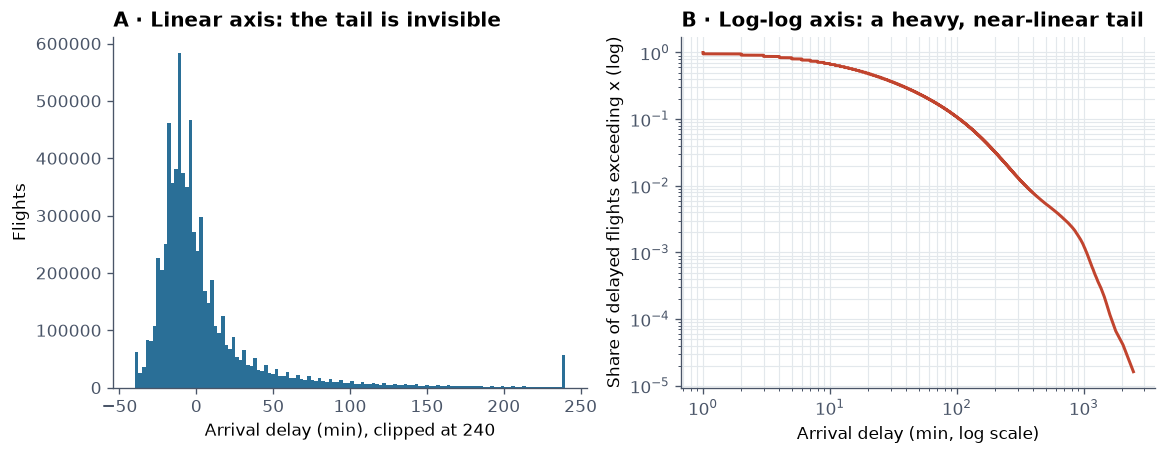

In [11]:
# pandas 3 returns read-only views, so sort a copy instead of in place.
pos = np.sort(df.loc[df["ArrDelayMinutes"] > 0, "ArrDelayMinutes"].to_numpy())
surv = 1 - np.arange(1, len(pos) + 1) / len(pos)
step = max(1, len(pos) // 40000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 3.8))
ax1.hist(np.clip(df["ArrDelay"], -40, 240), bins=120,
         color=FAMILY_COLORS["Internal"], edgecolor="none")
ax1.set_xlabel("Arrival delay (min), clipped at 240")
ax1.set_ylabel("Flights")
ax1.set_title("A · Linear axis: the tail is invisible", loc="left")

ax2.loglog(pos[::step], surv[::step], color=ACCENT, linewidth=1.8)
ax2.set_xlabel("Arrival delay (min, log scale)")
ax2.set_ylabel("Share of delayed flights exceeding x (log)")
ax2.set_title("B · Log-log axis: a heavy, near-linear tail", loc="left")
ax2.grid(color="#E3E8EC", linewidth=0.7, which="both")
ax2.set_axisbelow(True)
save_fig(fig, "fig12_distribution_shape")
plt.show()


## 7 · Three honest readings of the same data

| Audience | Reasonable statement | Chart that supports it |
|---|---|---|
| Passenger planning a trip | "Half of all flights arrive early" | median / ECDF |
| Passenger choosing a carrier | "About 1 in 69 flights is 3+ hours late" | tail probability |
| Airline operations | "The worst 1% absorbs a quarter of delay minutes" | Lorenz |

All three are true. They disagree in tone because they answer different
questions, and the dashboard therefore exposes **three** summary controls —
mean, median and tail share — rather than one.


In [12]:
pd.Series({
    "median_delay": float(df["ArrDelay"].median()),
    "mean_delay": float(df["ArrDelay"].mean()),
    "pct_early": float((df["ArrDelay"] < 0).mean() * 100),
    "pct_late60": float((df["ArrDelayMinutes"] >= 60).mean() * 100),
    "pct_late180": float((df["ArrDelayMinutes"] >= 180).mean() * 100),
    "worst1pct_share": float(cum_share[int(len(minutes) * 0.01) - 1]),
    "worst10pct_share": float(cum_share[int(len(minutes) * 0.10) - 1]),
    "corr_mean_vs_tail60": float(corr.loc["mean_delay", "pct_tail60"]),
    "spearman_carrier_mean_tail": float(rho),
}).to_csv(OUT_DIR / "key_findings_tail.csv")
print("saved outputs/key_findings_tail.csv")


saved outputs/key_findings_tail.csv


【中文导读】

**这一节最值得学的是"假设被推翻之后怎么办"。**

我们原本想论证"均值在改善、尾部在恶化"。数据显示月度均值与尾部概率的相关系数是 0.998 —— 几乎完全同向，这个说法在 2024 年的数据上不成立。三种选择：

1. 换个口径硬凑（挑几个"均值低但尾部高"的月份讲故事）→ 学术上不诚实，答辩一问就穿。
2. 删掉这一节 → 丢掉了一个很好的检验过程。
3. **如实报告零结果，并重新定义"均值的真正缺陷"** → 这才是专业做法。

我们选了第 3 条，结论改成三条站得住的：

- **集中度**：最差 1% 航班产生约 25% 的延误分钟（洛伦兹曲线）。
- **均值不是可定位的水平**：中位数约 −6 分钟（提前到），均值约 +7 分钟（晚到），均值落在第 58 百分位。
- **均值与风险没有固定换算关系**：均值在 −1.3 到 +18.1 分钟之间摆动（还会跨过零点），同期 ≥3 小时的概率从 0.64% 变到 2.63%。同样是"19 分钟的均值变化"，对乘客可能意味着"稍微差一点"，也可能是"误一整个下午的概率翻四倍"。

写进提案时，这种"我们检验过、没成立、于是改口径"的叙述比一个漂亮但站不住的结论值钱得多 —— 它证明你们真的做过研究，而不是在编故事。
